# 03 — Évaluation, choix du modèle et ablations

Ce notebook mesure la qualité des recommandations et justifie les choix du moteur par des expériences.

**Deux jeux de test** (dans `data/`) :

| Jeu | Contenu | Ce qu'il mesure |
|---|---|---|
| `paraphrases_test.csv` | 40 phrases, chacune décrivant **une** compétence **sans reprendre son vocabulaire** | la capacité d'une représentation à reconnaître le sens d'une phrase (tâche de recherche parmi 71 compétences) |
| `personas_test.json` | 25 profils complets (questionnaire rempli), 2 par métier, plus un cas de négation, avec le métier attendu | la qualité de la recommandation de bout en bout |

**Métriques** : *top-1* (le bon élément est classé premier), *top-3* ou *top-5* (il est dans les 3 ou 5 premiers),
*MRR* (moyenne de 1/rang : 1 = parfait, 0,5 = toujours deuxième).

**Plan**

1. Quelle représentation reconnaît le mieux une paraphrase ?
2. Quelle représentation recommande le mieux le métier ?
3. Le système complet : résultats détaillés
4. Ablations : que rapporte chaque composant ?
5. Sensibilité aux paramètres α et β
6. Robustesse : réponses courtes
7. Temps de calcul
8. Difficultés rencontrées et limites

In [1]:
# --- Mise en place : chemins, bibliothèques et style des graphiques ---
import sys, warnings, os
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

RACINE = Path.cwd().parent            # le notebook est dans notebooks/, le code dans src/
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

# Palette catégorielle (ordre fixe, validée pour le daltonisme) et couleurs d'encre
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT, VIOLET, ROUGE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]
SERIES = [BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT, VIOLET, ROUGE]
ENCRE, ENCRE_2, MUET, GRILLE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "text.color": ENCRE, "axes.labelcolor": ENCRE_2, "xtick.color": MUET, "ytick.color": MUET,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

In [2]:
import time
from src import config
from src.referentiel import Referentiel
from src.embeddings import encodeur_sbert, EncodeurTFIDF, EncodeurMotsStatiques
from src.moteur import MoteurRecommandation
from src.evaluation import charger_personas, evaluer, tableau_comparatif, bornes_calibration, separation

ref = Referentiel.charger()
personas = charger_personas()
paraphrases = pd.read_csv(RACINE / "data/paraphrases_test.csv")
corpus = ref.competences["texte_embedding"].tolist() + ref.metiers["texte_embedding"].tolist()

encodeurs = {
    "TF-IDF (lexical)": EncodeurTFIDF(corpus),
    "fastText (moyenne de mots)": EncodeurMotsStatiques(),
    "SBERT MiniLM (retenu)": encodeur_sbert(config.MODELE_SBERT),
    "SBERT mpnet (plus gros)": encodeur_sbert(config.MODELE_SBERT_GRAND),
}
print(f"{len(paraphrases)} paraphrases | {len(personas)} personas | {len(encodeurs)} représentations comparées")

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-mpnet-base-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

40 paraphrases | 25 personas | 4 représentations comparées


## 1. Quelle représentation reconnaît le mieux une paraphrase ?

Pour chacune des 40 phrases, on classe les 71 compétences par similarité cosinus et on regarde le rang de la bonne.
Exemple de phrase : « *J'ai regroupé les clients en familles de comportements sans savoir à l'avance combien il y
en aurait* » → *Apprentissage non supervisé*. Aucun mot de la compétence (« clustering », « k-means », « ACP »)
n'apparaît dans la phrase.

,top-1,top-5,MRR,rang médian
TF-IDF (lexical),22%,40%,0.317,18
fastText (moyenne de mots),20%,48%,0.344,7
SBERT MiniLM (retenu),35%,65%,0.493,2
SBERT mpnet (plus gros),45%,70%,0.563,2


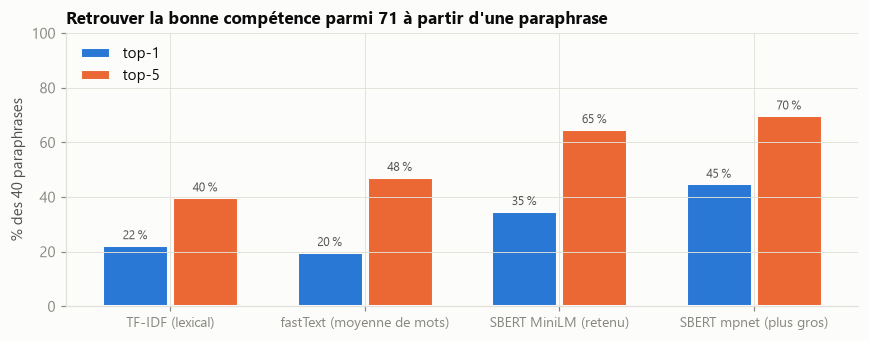

In [3]:
ids = ref.ids_competences
resultats_para, rangs_para = {}, {}
for nom, enc in encodeurs.items():
    sim = enc.encoder(paraphrases["phrase"].tolist()) @ enc.encoder(ref.competences["texte_embedding"].tolist()).T
    rangs = np.array([int(np.where(np.argsort(-sim[i]) == ids.index(c))[0][0]) + 1
                      for i, c in enumerate(paraphrases["competence_id"])])
    rangs_para[nom] = rangs
    resultats_para[nom] = {"top-1": np.mean(rangs == 1), "top-5": np.mean(rangs <= 5), "MRR": np.mean(1 / rangs),
                           "rang médian": np.median(rangs)}
tab_para = pd.DataFrame(resultats_para).T
display(tab_para.style.format({"top-1": "{:.0%}", "top-5": "{:.0%}", "MRR": "{:.3f}", "rang médian": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(tab_para))
for k, (col, couleur) in enumerate([("top-1", BLEU), ("top-5", ORANGE)]):
    barres = ax.bar(x + (k - 0.5) * 0.36, tab_para[col] * 100, width=0.34, color=couleur, label=col, edgecolor=SURFACE, linewidth=2)
    ax.bar_label(barres, fmt="%.0f %%", fontsize=8, color=ENCRE_2, padding=2)
ax.set_xticks(x, tab_para.index, fontsize=9); ax.set_ylim(0, 100); ax.set_ylabel("% des 40 paraphrases")
ax.set_title("Retrouver la bonne compétence parmi 71 à partir d'une paraphrase"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [4]:
# Exemples : quelles paraphrases sont retrouvées par SBERT mais pas par TF-IDF, et inversement ?
detail_para = paraphrases.assign(**{f"rang {k.split(' (')[0]}": v for k, v in rangs_para.items()})
detail_para["compétence"] = detail_para["competence_id"].map(ref.competences.set_index("competence_id")["competence"])
cols = ["phrase", "compétence", "rang TF-IDF", "rang fastText", "rang SBERT MiniLM", "rang SBERT mpnet"]
print("SBERT MiniLM dans le top 5, TF-IDF au-delà du rang 10 :")
display(detail_para[(detail_para["rang SBERT MiniLM"] <= 5) & (detail_para["rang TF-IDF"] > 10)][cols].head(8))
print("Les plus difficiles pour SBERT MiniLM :")
display(detail_para.sort_values("rang SBERT MiniLM", ascending=False)[cols].head(5))

SBERT MiniLM dans le top 5, TF-IDF au-delà du rang 10 :


,phrase,compétence,rang TF-IDF,rang fastText,rang SBERT MiniLM,rang SBERT mpnet
0,Je remettais au propre des fichiers clients pleins de trous et de lignes répétées.,Nettoyage et préparation des données,19,1,4,2
2,Je fouille un nouveau fichier pour voir ce qui ressort et ce qui cloche avant toute ét...,Analyse exploratoire des données,20,4,2,1
3,J'ai vérifié que l'écart entre les deux groupes n'était pas dû au hasard.,Tests statistiques et inférence,22,7,2,1
5,J'ai estimé combien de colis l'entrepôt recevrait chaque semaine du trimestre prochain.,Prévision et séries temporelles,25,19,1,1
14,J'ai mesuré combien de vrais cas l'algorithme retrouvait et combien de fausses alertes...,Évaluation de modèles,38,14,2,8
16,Notre site propose à chaque visiteur des articles proches de ceux qu'il a déjà aimés.,Systèmes de recommandation,40,31,2,1
19,Mon programme repère automatiquement les rayures sur des photos de carrosserie.,Vision par ordinateur,44,1,1,1
24,Mon outil devine si un avis client est content ou mécontent.,Classification de textes et analyse de sentiments,51,27,4,14


Les plus difficiles pour SBERT MiniLM :


,phrase,compétence,rang TF-IDF,rang fastText,rang SBERT MiniLM,rang SBERT mpnet
23,J'ai réentraîné un gros modèle pré-entraîné sur nos propres documents juridiques.,Transformers et modèles de langage,8,17,44,61
4,J'ai comparé deux versions d'une page web sur deux moitiés du trafic pour voir laquell...,Plan d'analyse et expérimentation,23,53,33,37
10,J'ai appris à un programme à reconnaître les messages frauduleux à partir d'exemples é...,Classification supervisée,38,37,27,6
13,"J'ai inventé de nouvelles colonnes, comme l'ancienneté du client, pour aider l'algorit...",Feature engineering,37,2,26,5
32,J'empaquette l'application avec toutes ses dépendances pour qu'elle tourne de la même ...,Conteneurisation,2,10,25,1


> **Interprétation.** Sur 40 paraphrases, les embeddings de phrases dominent nettement. SBERT MiniLM retrouve la bonne compétence en premier dans 35 % des cas et dans le top 5 dans 65 % des cas. TF-IDF est à 22 % et 40 %, fastText à 20 % et 48 %. Le plus gros modèle, SBERT mpnet, monte à 45 % et 70 %.
>
> Le hasard donnerait 1/71 ≈ 1,4 % en top-1. La tâche est difficile : plusieurs compétences sont voisines (*Classification supervisée*, *Évaluation de modèles*, *Feature engineering* décrivent souvent la même phrase), si bien qu'un rang 2 ou 3 reste souvent une réponse raisonnable. C'est pourquoi le top-5 est plus parlant que le top-1 ici.
>
> Les exemples confirment le mécanisme. « *J'ai estimé combien de colis l'entrepôt recevrait chaque semaine du trimestre prochain* » ne partage aucun mot avec *Prévision et séries temporelles* : TF-IDF la classe 25e, SBERT 1re. Les échecs de SBERT sont instructifs aussi. « *J'ai réentraîné un gros modèle pré-entraîné sur nos documents juridiques* » est une description de *fine-tuning* trop indirecte pour le petit modèle (rang 44). « *J'empaquette l'application avec ses dépendances* » n'est retrouvée qu'au rang 25 par MiniLM, mais au rang 1 par mpnet : un modèle plus gros capte des paraphrases plus lointaines.

## 2. Quelle représentation recommande le mieux le métier ?

On fait maintenant tourner **tout le moteur** avec chaque représentation sur les 25 personas. Pour une comparaison
équitable, les bornes de calibration sont **mesurées pour chaque représentation** avec la même procédure
(`bornes_calibration`, voir notebook 02), car chaque méthode a sa propre échelle de cosinus.

Deux conditions :

- **texte libre seul** : seules les phrases rédigées par l'utilisateur servent de preuves, sans Likert ni
  objectif. C'est le test le plus pur de l'analyse sémantique ;
- **système complet** : texte, outils cochés, questions guidées, Likert et objectif.

In [5]:
texte_seul = frozenset({"texte"})
res_metiers, bornes = {}, {}
for nom, enc in encodeurs.items():
    for condition, kw, sources in [("texte libre seul", dict(utiliser_likert=False, utiliser_objectif=False, sources=texte_seul), texte_seul),
                                   ("système complet", {}, None)]:
        bas, haut = bornes_calibration(enc, ref, personas, sources=sources)
        moteur_test = MoteurRecommandation(ref, enc, cos_bas=bas, cos_haut=haut, **kw)
        met, _ = evaluer(moteur_test, personas)
        res_metiers[(nom, condition)] = met
        bornes[(nom, condition)] = (round(bas, 2), round(haut, 2))
tab = tableau_comparatif(res_metiers)
tab["bornes (bas, haut)"] = [bornes[k] for k in res_metiers]
display(tab)

top-1  top-3    MRR  rang moyen bornes (bas, haut)
TF-IDF (lexical)           texte libre seul   72 %   96 %  0.820        1.60        (0.0, 0.14)
                           système complet    92 %  100 %  0.960        1.08        (0.0, 0.35)
fastText (moyenne de mots) texte libre seul   32 %   60 %  0.520        3.12        (0.75, 0.8)
                           système complet    76 %  100 %  0.873        1.28       (0.76, 0.86)
SBERT MiniLM (retenu)      texte libre seul   76 %   96 %  0.853        1.48       (0.32, 0.48)
                           système complet    96 %  100 %  0.980        1.04       (0.35, 0.65)
SBERT mpnet (plus gros)    texte libre seul   52 %   92 %  0.702        1.96        (0.34, 0.5)
                           système complet   100 %  100 %  1.000        1.00       (0.37, 0.69)

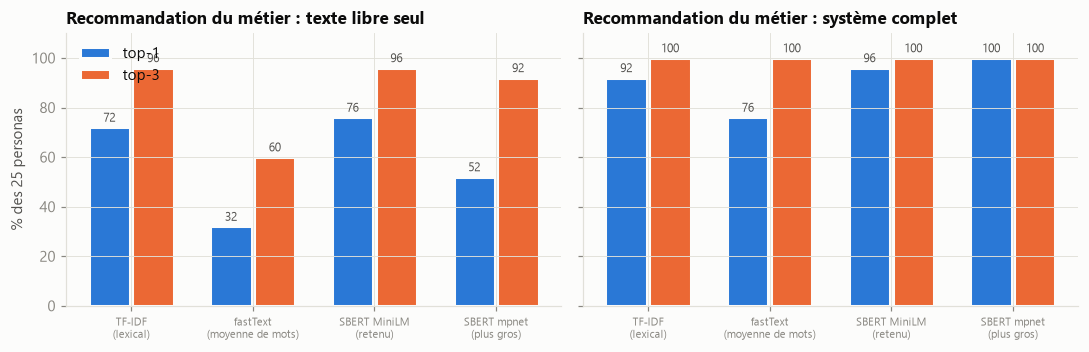

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, condition in zip(axes, ["texte libre seul", "système complet"]):
    vals = [res_metiers[(n, condition)] for n in encodeurs]
    x = np.arange(len(encodeurs))
    for k, (col, couleur) in enumerate([("top-1", BLEU), ("top-3", ORANGE)]):
        b = ax.bar(x + (k - 0.5) * 0.36, [v[col] * 100 for v in vals], width=0.34, color=couleur, label=col, edgecolor=SURFACE, linewidth=2)
        ax.bar_label(b, fmt="%.0f", fontsize=8, color=ENCRE_2, padding=2)
    ax.set_xticks(x, [n.replace(" (", "\n(") for n in encodeurs], fontsize=7.5); ax.set_ylim(0, 110)
    ax.set_title(f"Recommandation du métier : {condition}")
axes[0].set_ylabel("% des 25 personas"); axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

> **Interprétation.** Deux constats, et un vrai compromis.
>
> 1. **Sur le texte libre seul, SBERT MiniLM est le meilleur** (76 % en top-1, 96 % en top-3), devant TF-IDF (72 %), loin devant fastText (32 %) et, de façon surprenante, devant le gros modèle mpnet (52 %). C'est le test le plus pur de l'analyse sémantique, puisque rien d'autre que les phrases de l'utilisateur n'est utilisé. fastText souffre de son échelle de cosinus écrasée (bornes 0,75 / 0,80) : tout se ressemble, comme on l'a vu dans le notebook 02.
> 2. **Sur le système complet, tout le monde progresse**, car les outils cochés, les questions guidées et le Likert apportent une information structurée. mpnet atteint 100 %, MiniLM 96 %, TF-IDF 92 %. L'écart entre MiniLM et mpnet est **d'un seul persona sur 25** : ce n'est pas significatif.
> 3. **TF-IDF est bon sur le système complet pour une raison qui ne tient pas en situation réelle.** Les phrases associées aux outils cochés ont été rédigées par nous, avec le même vocabulaire que le référentiel. Sur le texte libre seul, son avance disparaît, et le test de paraphrases montre ce qu'il ne sait pas faire.
>
> **Choix retenu : SBERT MiniLM.** Il est le meilleur sur le texte libre, à un persona du meilleur sur le système complet, et 2,5 fois plus léger que mpnet (≈ 470 Mo contre ≈ 1,1 Go), donc plus rapide sur un CPU d'ordinateur portable pendant la démonstration. mpnet reste une option documentée : il suffit de changer `MODELE_SBERT` dans `src/config.py` et de remesurer les bornes de calibration.

## 3. Le système complet : résultats détaillés

Configuration retenue : SBERT MiniLM, paramètres de `src/config.py`.

In [7]:
moteur = MoteurRecommandation(ref, encodeurs["SBERT MiniLM (retenu)"])
met, detail = evaluer(moteur, personas)
print({k: round(v, 3) for k, v in met.items()})
noms = ref.metiers.set_index("metier_id")["metier"]
detail["attendu"] = detail["attendu"].map(noms); detail["predit"] = detail["predit"].map(noms)
display(detail.round(3))

{'top-1': 0.96, 'top-3': 1.0, 'MRR': 0.98, 'rang moyen': 1.04}


,persona,description,attendu,predit,rang_attendu,score_predit,ecart_1_2
0,P01,Analyste marketing en alternance,Data Analyst,Data Analyst,1,0.531,0.055
1,P02,Stagiaire en statistique dans une mutuelle,Data Analyst,Data Analyst,1,0.538,0.092
2,P03,Ingénieur IA chez un assureur,Data Scientist,Data Scientist,1,0.638,0.097
3,P04,Docteur en biologie reconverti,Data Scientist,Data Scientist,1,0.518,0.053
4,P05,Développeur back-end passé en plateforme data,Data Engineer,Data Engineer,1,0.717,0.090
5,P06,Alternant ingénieur en logistique,Data Engineer,Data Engineer,1,0.711,0.020
6,P07,Ingénieur vision industrielle,Ingénieur Machine Learning,Ingénieur Machine Learning,1,0.593,0.018
7,P08,Ingénieur recommandation (streaming),Ingénieur Machine Learning,Ingénieur Machine Learning,1,0.652,0.168
8,P09,Linguiste spécialisée en TAL,Ingénieur NLP,Ingénieur NLP,1,0.713,0.324
9,P10,Développeur d'assistants conversationnels,Ingénieur NLP,Ingénieur NLP,1,0.533,0.054


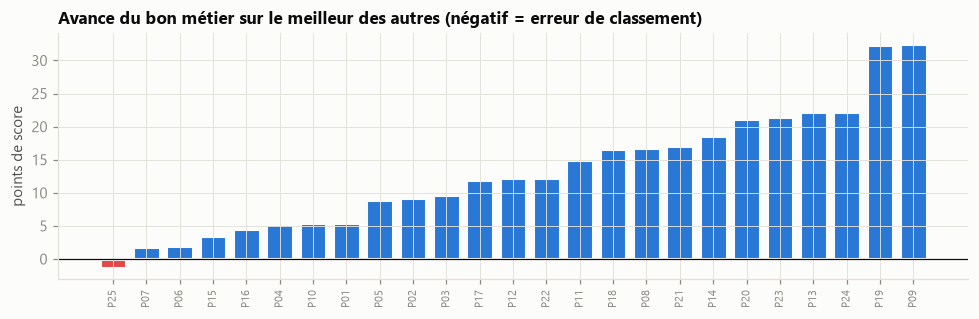

Avance moyenne : 13.1 points | minimum : -1.4 | personas sous 2 points : 2


In [8]:
ecarts = separation(moteur, personas)
fig, ax = plt.subplots(figsize=(9, 3))
ordre = np.argsort(ecarts)
couleurs = [BLEU if e > 0 else ROUGE for e in ecarts[ordre]]
ax.bar(range(len(ecarts)), ecarts[ordre] * 100, color=couleurs, edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(len(ecarts)), [personas[i]["id"] for i in ordre], fontsize=7, rotation=90)
ax.axhline(0, color=ENCRE, lw=0.8)
ax.set_ylabel("points de score"); ax.set_title("Avance du bon métier sur le meilleur des autres (négatif = erreur de classement)")
plt.tight_layout(); plt.show()
print(f"Avance moyenne : {ecarts.mean() * 100:.1f} points | minimum : {ecarts.min() * 100:.1f} | personas sous 2 points : {(ecarts < 0.02).sum()}")

> **Interprétation.** 24 personas sur 25 ont le bon métier en tête (top-1 96 %) et tous l'ont dans le top 3. L'avance moyenne du bon métier sur le suivant est de 13,1 points de score.
>
> - **La seule erreur est P25**, le cas de négation : un chargé d'études en collectivité qui écrit des requêtes, corrige des données et produit des graphiques. Il est classé Développeur BI avec 1,4 point d'avance sur Data Analyst. Les deux métiers partagent SQL, la préparation des données et la visualisation, et le profil est réellement à la frontière.
> - **Les décisions les plus serrées** (moins de 2 points) concernent P07 (vision industrielle : ML Engineer contre MLOps, puisqu'il a aussi mis son modèle en production) et P06 (alternant data engineer, proche de l'Architecte base de données). Ce sont des voisins naturels. Le top 3 et le score de chaque métier rendent cette proximité visible à l'utilisateur au lieu de la cacher.
> - **Les décisions les plus nettes** (plus de 30 points) concernent les profils très typés : P09 (TAL) et P19 (développeur full-stack).

## 4. Ablations : que rapporte chaque composant ?

On retire un composant à la fois du système complet. Une baisse de performance montre que le composant est utile.

In [9]:
sbert = encodeurs["SBERT MiniLM (retenu)"]
configurations = {
    "Système complet (retenu)": {},
    "sans détection de la négation": dict(utiliser_negation=False),
    "sans auto-évaluation (Likert)": dict(utiliser_likert=False),
    "sans objectif professionnel": dict(utiliser_objectif=False),
    "sans outils cochés ni « oui » guidés": dict(sources=frozenset({"texte"})),
    "compétence = libellé seul (sans description)": dict(texte_competence="libelle"),
    "agrégation du pseudocode du sujet (moyenne par bloc)": dict(agregation="moyenne_phrases"),
    "β = 0,8 (objectif plus influent)": dict(beta=0.8),
    "α = 1 (Likert ignoré dans le score)": dict(alpha=1.0),
    "α = 0,5 (Likert aussi important que le texte)": dict(alpha=0.5),
}
res_abl = {nom: evaluer(MoteurRecommandation(ref, sbert, **kw), personas)[0] for nom, kw in configurations.items()}
sep_abl = {nom: separation(MoteurRecommandation(ref, sbert, **kw), personas).mean() for nom, kw in configurations.items()}
tab_abl = tableau_comparatif(res_abl)
tab_abl["avance moyenne (points)"] = [round(sep_abl[n] * 100, 1) for n in res_abl]
display(tab_abl)

,top-1,top-3,MRR,rang moyen,avance moyenne (points)
Système complet (retenu),96 %,100 %,0.98,1.04,13.1
sans détection de la négation,96 %,100 %,0.98,1.04,13.2
sans auto-évaluation (Likert),88 %,100 %,0.94,1.12,11.7
sans objectif professionnel,96 %,100 %,0.98,1.04,12.5
sans outils cochés ni « oui » guidés,92 %,100 %,0.96,1.08,10.6
compétence = libellé seul (sans description),80 %,96 %,0.89,1.28,9.0
agrégation du pseudocode du sujet (moyenne par bloc),88 %,96 %,0.93,1.20,8.3
"β = 0,8 (objectif plus influent)",88 %,100 %,0.94,1.12,12.5
α = 1 (Likert ignoré dans le score),88 %,100 %,0.94,1.12,11.7
"α = 0,5 (Likert aussi important que le texte)",96 %,100 %,0.98,1.04,13.4


> **Interprétation.** Chaque ligne retire un composant, et les écarts d'un persona (4 points de top-1) sont à lire avec prudence.
>
> - **La description des compétences est le composant le plus utile** : avec le libellé seul, le top-1 tombe à 80 % et l'avance moyenne passe de 13,1 à 9,0 points. Cela confirme le choix du notebook 01 : enrichir le ROME avec une phrase « comme une expérience vécue ».
> - **L'agrégation par compétence bat celle du pseudocode du sujet** : avec la moyenne par bloc, on obtient 88 % en top-1, un persona sort même du top 3, et l'avance tombe à 8,3 points, la plus faible de toutes les variantes. Avec la moyenne, les phrases hors sujet diluent les scores.
> - **L'auto-évaluation (Likert) aide** : sans elle, 88 %. Le texte reste dominant (α = 0,75), mais le Likert donne une information sur les blocs que l'utilisateur n'a pas pensé à décrire.
> - **Les outils cochés et les questions guidées apportent un peu** (92 % sans eux, avance de 10,6 au lieu de 13,1).
> - **L'objectif professionnel n'améliore pas le top-1** à β = 0,9 et augmente légèrement l'avance (13,1 contre 12,5). Plus influent (β = 0,8), il fait perdre deux personas. Il est donc bien réglé en départage.
> - **La détection de la négation ne change rien sur ces 25 personas.** C'est cohérent avec le notebook 02 : SBERT repousse déjà les deux phrases négatives de P25 sous le seuil. Le filtre reste un garde-fou pour les phrases que SBERT ne repousse pas (4 sur 8 dans le test du notebook 02).

## 5. Sensibilité aux paramètres α et β

α règle le poids de l'analyse sémantique face à l'auto-évaluation ; β règle le poids de la couverture face à
l'affinité avec l'objectif. On balaie une grille de valeurs pour vérifier que le choix (α = 0,75 ; β = 0,9) n'est
pas un réglage fragile.

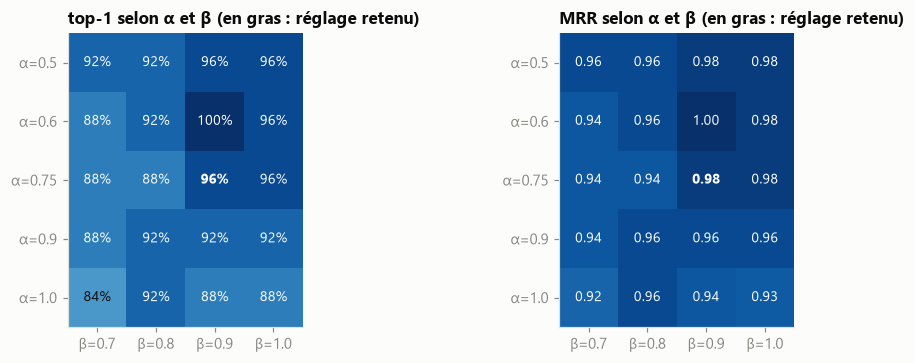

In [10]:
alphas, betas = [0.5, 0.6, 0.75, 0.9, 1.0], [0.7, 0.8, 0.9, 1.0]
grille_mrr = pd.DataFrame(index=alphas, columns=betas, dtype=float)
grille_top1 = grille_mrr.copy()
for a in alphas:
    for b in betas:
        m_, _ = evaluer(MoteurRecommandation(ref, sbert, alpha=a, beta=b), personas)
        grille_mrr.at[a, b], grille_top1.at[a, b] = m_["MRR"], m_["top-1"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, g, titre in [(axes[0], grille_top1, "top-1"), (axes[1], grille_mrr, "MRR")]:
    im = ax.imshow(g.values.astype(float), cmap="Blues", vmin=0.6, vmax=1.0)
    ax.set_xticks(range(len(betas)), [f"β={b}" for b in betas]); ax.set_yticks(range(len(alphas)), [f"α={a}" for a in alphas])
    for i in range(len(alphas)):
        for j in range(len(betas)):
            v = g.values[i, j]
            ax.text(j, i, f"{v:.0%}" if titre == "top-1" else f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.85 else ENCRE, fontweight="bold" if (alphas[i], betas[j]) == (0.75, 0.9) else None)
    ax.grid(False); ax.set_title(f"{titre} selon α et β (en gras : réglage retenu)")
plt.tight_layout(); plt.show()

> **Interprétation.** Les résultats forment un **plateau** autour du réglage retenu : pour β = 0,9 ou 1,0 et α entre 0,5 et 0,75, le top-1 vaut 96 % presque partout. Le choix n'est donc pas un réglage fragile. Deux tendances nettes se dégagent : un β faible (objectif trop influent) dégrade le classement, et α = 1 (Likert ignoré) aussi.
>
> La case α = 0,6 ; β = 0,9 atteint 100 %. Nous ne l'avons **pas** retenue : choisir le meilleur point sur 25 personas reviendrait à sur-ajuster nos paramètres à notre propre jeu de test (le même biais de sélection que celui discuté dans le TP3). Un écart d'un persona n'est pas significatif, et nous préférons garder l'analyse des textes nettement dominante.

## 6. Robustesse : que se passe-t-il si l'utilisateur répond peu ?

Dans la réalité, beaucoup d'utilisateurs écrivent peu. On simule deux questionnaires appauvris :

- **projet seul** : on ne garde que la réponse à la question « racontez un projet », sans les autres textes ni les
  précisions ;
- **fermé seul** : aucun texte libre, seulement les outils cochés, les « oui » guidés et le Likert.

In [11]:
import copy

def appauvrir(p, mode):
    q = copy.deepcopy(p)
    r = q["reponses"]
    if mode == "projet seul":
        r["textes"] = {"projet": r["textes"]["projet"]}
        for g in r.get("guidees", {}).values():
            g["precision"] = ""
    elif mode == "fermé seul":
        r["textes"] = {}
        r["objectif"] = ""
        for g in r.get("guidees", {}).values():
            g["precision"] = ""
    return q

res_rob = {"questionnaire complet": evaluer(moteur, personas)[0]}
for mode in ["projet seul", "fermé seul"]:
    res_rob[mode] = evaluer(moteur, [appauvrir(p, mode) for p in personas])[0]
display(tableau_comparatif(res_rob))

,top-1,top-3,MRR,rang moyen
questionnaire complet,96 %,100 %,0.98,1.04
projet seul,96 %,100 %,0.98,1.04
fermé seul,84 %,100 %,0.90,1.28


> **Interprétation.**
>
> - **Avec le projet seul, la performance ne baisse pas** (96 %). Une description de projet concrète, complétée par les outils et le Likert, suffit à situer le profil. C'est rassurant pour un utilisateur pressé. Les autres questions ouvertes servent surtout à **expliquer** le résultat (plus de citations possibles) et à affiner les scores par compétence.
> - **Sans aucun texte libre, le top-1 tombe à 84 %.** Les réponses fermées seules situent grossièrement le profil, mais ne suffisent pas à départager des métiers voisins. C'est la justification concrète de l'exigence du sujet : le questionnaire ne doit pas se limiter à des valeurs numériques.

## 7. Temps de calcul

In [12]:
t0 = time.perf_counter()
for p in personas:
    moteur.analyser(p["reponses"])
duree = (time.perf_counter() - t0) / len(personas)
print(f"Analyse complète d'un questionnaire : {duree * 1000:.0f} ms en moyenne (CPU, sans GPU)")

Analyse complète d'un questionnaire : 258 ms en moyenne (CPU, sans GPU)


> **Interprétation.** Moins d'une seconde par questionnaire sur un CPU d'ordinateur portable : encodage d'une quinzaine de phrases, produit matriciel 15 × 71 et quelques agrégations. Le seul coût notable est le chargement initial du modèle (quelques secondes), fait une fois par session grâce au cache de Streamlit.

## 8. Difficultés rencontrées et limites

| Difficulté | Comment nous l'avons traitée |
|---|---|
| **Le cosinus SBERT n'est pas un pourcentage** : deux phrases sans rapport ont 0,2 à 0,3 | calibration linéaire bornée, bornes mesurées sur des profils de test (notebook 02) |
| **Une réponse longue mélange plusieurs compétences** et son embedding devient flou | découpage en phrases puis en propositions, agrégation par maximum |
| **Les phrases hors sujet faisaient baisser les scores** avec l'agrégation du pseudocode du sujet | agrégation par compétence (maximum sur les preuves) ; mesuré dans l'ablation ci-dessus |
| **La négation** (« je n'ai jamais fait de NLP ») | SBERT la capte partiellement ; filtre par règles en complément (notebook 02) |
| **Le ROME est générique** et ne décrit pas les métiers NLP ou MLOps | enrichissement des descriptions et ajouts documentés (notebook 01) |
| **L'objectif professionnel trompait le classement** quand il pesait 20 % | les métiers sont représentés par plusieurs phrases (missions) et l'affinité ne pèse que 10 % |
| **TF-IDF semblait aussi bon que SBERT** dans un premier test | les phrases des outils cochés reprenaient le vocabulaire du référentiel ; l'évaluation « texte libre seul » et le test de paraphrases isolent l'apport sémantique |
| **Le modèle est en anglais dans l'exemple du sujet** (all-MiniLM-L6-v2) alors que nos utilisateurs écrivent en français | modèle multilingue entraîné sur des paraphrases |

**Limites**

- **Biais d'évaluation** : les personas et le référentiel ont été écrits par la même équipe. Malgré l'effort de
  paraphrase, les personas ressemblent plus au référentiel que de vraies réponses. Il faudrait des réponses réelles
  annotées par un tiers. Le questionnaire enregistre les réponses (`data/reponses/`) pour le permettre.
- **25 personas** : un écart de 1 persona vaut 4 points de top-1. Les différences de moins de 2 personas entre deux
  configurations ne sont pas significatives.
- **Couverture ≠ niveau** : la similarité mesure si une compétence est *évoquée et décrite*, pas si elle est
  maîtrisée à un niveau expert. Le Likert compense en partie.
- **Négation par règles** : elle ne gère pas l'ironie ni les négations implicites (« j'ai toujours évité le cloud »).